In [2]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
# nice plotting function with cartopy and coastlines. Use robinson projection
import cartopy.crs as ccrs
import cartopy.feature as cf
import matplotlib.pyplot as plt

def truncate_colormap(cmap, minval=0.0, maxval=1.0, n=100):
    new_cmap = colors.LinearSegmentedColormap.from_list(
        'trunc({n},{a:.2f},{b:.2f})'.format(n=cmap.name, a=minval, b=maxval),
        cmap(np.linspace(minval, maxval, n)))
    return new_cmap

def plot_map(dataarray, title='', cmap='viridis', cmap_split = '', vmin=None, vmax=None, borders=False, norm=None, cbar_label= '', svg=False):
    
    if cmap_split=='low':
         cmap = truncate_colormap(plt.get_cmap(cmap), 0.0, 0.5)
    elif cmap_split=='high':
        cmap = truncate_colormap(plt.get_cmap(cmap), 0.5, 1.0)
    else:
        cmap = plt.get_cmap(cmap)

    if cbar_label=='':
        cbar_label = dataarray.name
    
    plt.figure(figsize=(21, 7))
    ax = plt.axes(projection=ccrs.Robinson())
    dataarray.plot(ax=ax, cmap=cmap, vmin=vmin, vmax=vmax, norm=norm, cbar_kwargs={'label': cbar_label}, transform=ccrs.PlateCarree())
    ax.coastlines() # coastlines for context
    if borders: # country borders toggle
        ax.add_feature(cf.BORDERS)
    ax.set_title(title)
    if svg:
        plt.savefig("../export/map_{}.svg".format(dataarray.name), format='svg', bbox_inches='tight')
    plt.show()

# function for calculating glomal mean and std of a given dataarray, both weighted and unweighted
# weight by grid cell area calculated using earth's radius and latitude. i.e. create a weight array with same lat and lon dimensions as da, where weights = cos(lat) and then use xarray's weighted function to calculate mean and std
# area = R * (max_lat - min_lat) * (max_lon - min_lon) * cos(lat) where R is Earth's radius and lat is the latitude of the grid cell in radians.
# Since we are only interested in relative weights, we can ignore the constant R and the lat/lon differences and just use weights = cos(lat) for each grid cell.
def global_stats(da, weighted=True):
    if weighted:
        weights = np.cos(np.deg2rad(da['lat']))
        weighted_da = da.weighted(weights)
        mean = weighted_da.mean(dim=['lat', 'lon'])
        std = weighted_da.std(dim=['lat', 'lon'])
    else:
        mean = da.mean(dim=['lat', 'lon'])
        std = da.std(dim=['lat', 'lon'])
    return mean, std

In [3]:
SCENARIOS = [
    {'name': 'Present', 'clim': '1991_2020', 'lu': '1991_2020'},
    {'name': 'Historical', 'clim': '1961_1990', 'lu': '1961_1990'},
    {'name': 'PI_Mix1', 'clim': '1901_1930', 'lu': 'pre-industrial'},
    {'name': 'PI_Mix2', 'clim': '1991_2020', 'lu': 'pre-industrial'},
    {'name': 'PI_Mix3', 'clim': '1901_1930', 'lu': '1991_2020'},
]

In [5]:
lai_Clim_PI_LU_PI = xr.open_dataset('../output_lai/lai_pi_mix1_ensemble_mean.nc').lai_95th
lai_Clim_Pres_LU_PI = xr.open_dataset('../output_lai/lai_pi_mix2_ensemble_mean.nc').lai_95th
lai_Clim_PI_LU_Pres = xr.open_dataset('../output_lai/lai_pi_mix3_ensemble_mean.nc').lai_95th
lai_Clim_Pres_LU_Pres = xr.open_dataset('../output_lai/lai_present_oos_mosaic.nc').lai_95th

In [6]:
deltaLAI = lai_Clim_Pres_LU_Pres - lai_Clim_PI_LU_PI
deltaLAI_clim = lai_Clim_Pres_LU_PI - lai_Clim_PI_LU_PI
deltaLAI_lu = lai_Clim_PI_LU_Pres - lai_Clim_PI_LU_PI
deltaLAI_interaction = deltaLAI - deltaLAI_clim - deltaLAI_lu

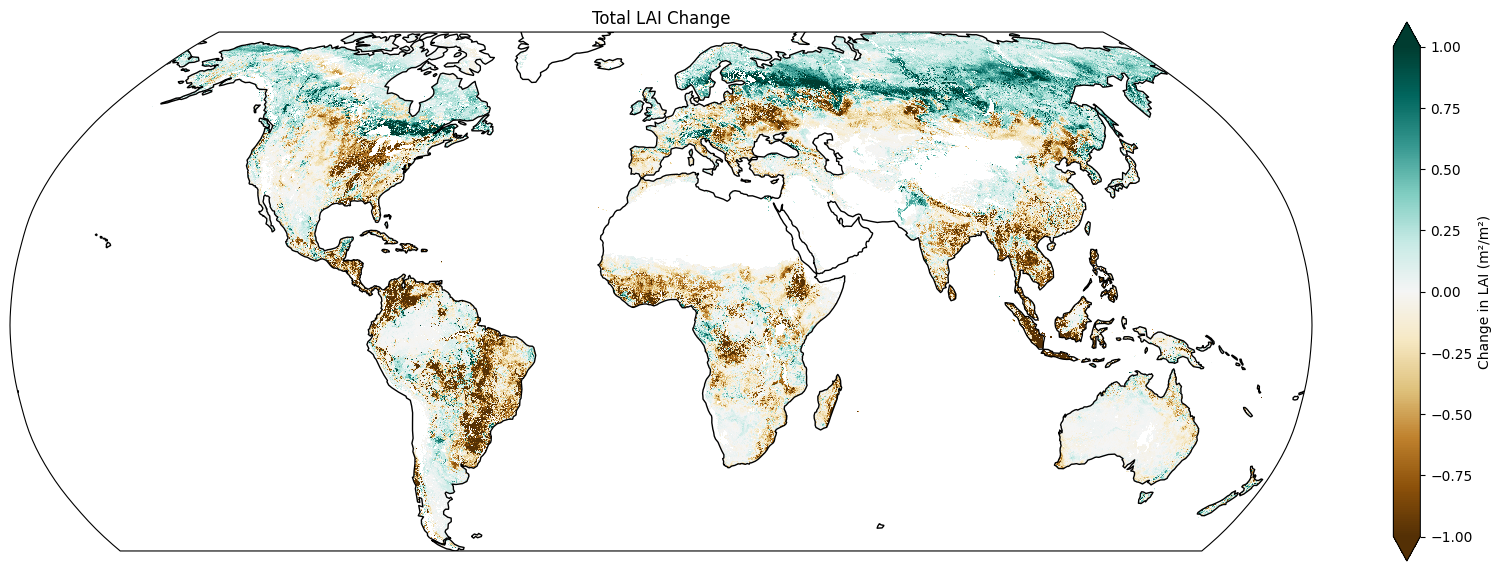

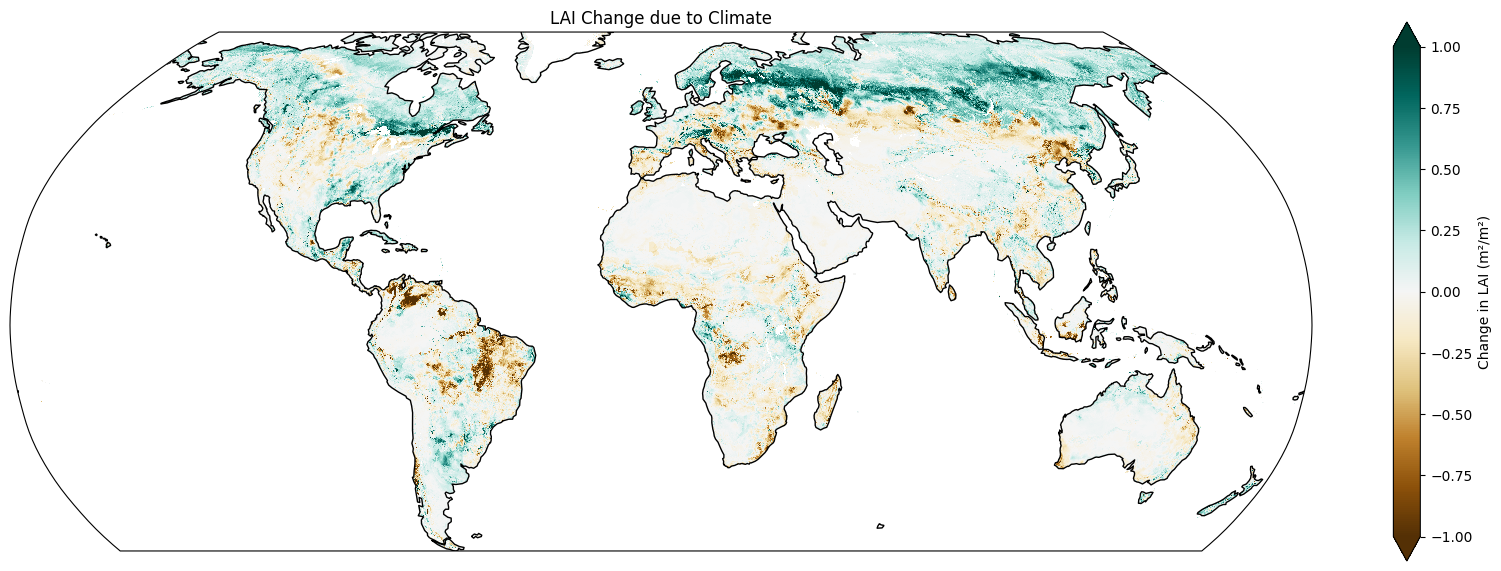

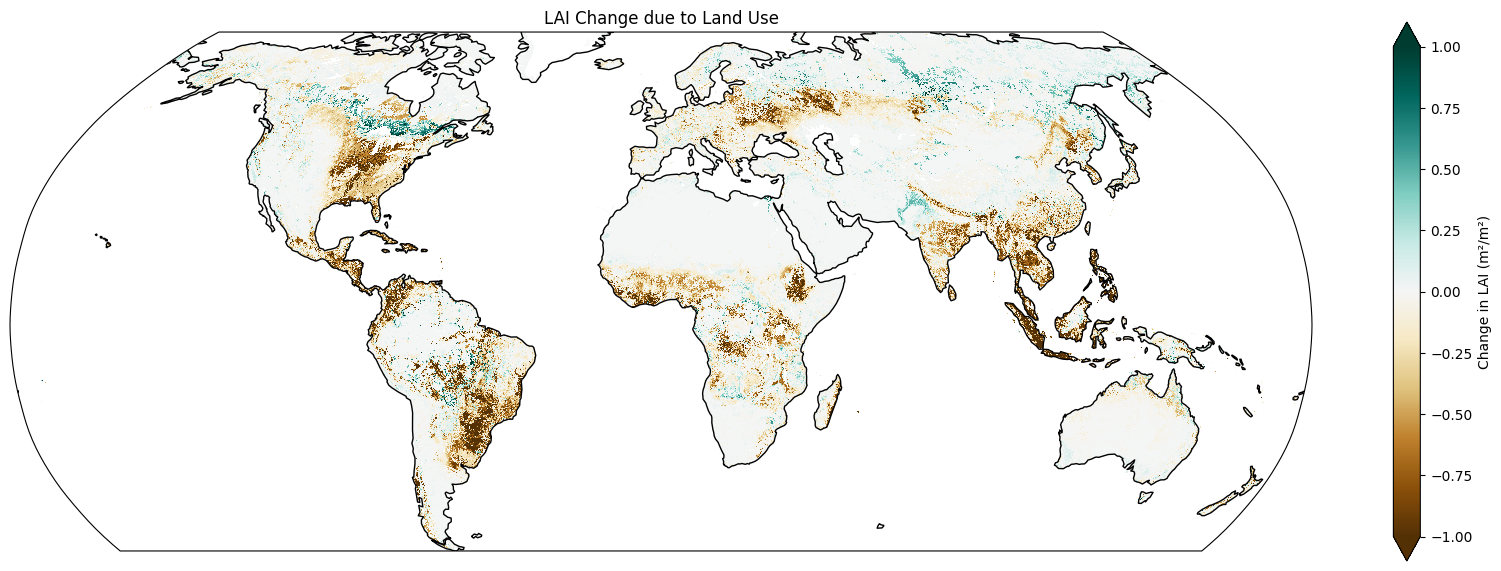

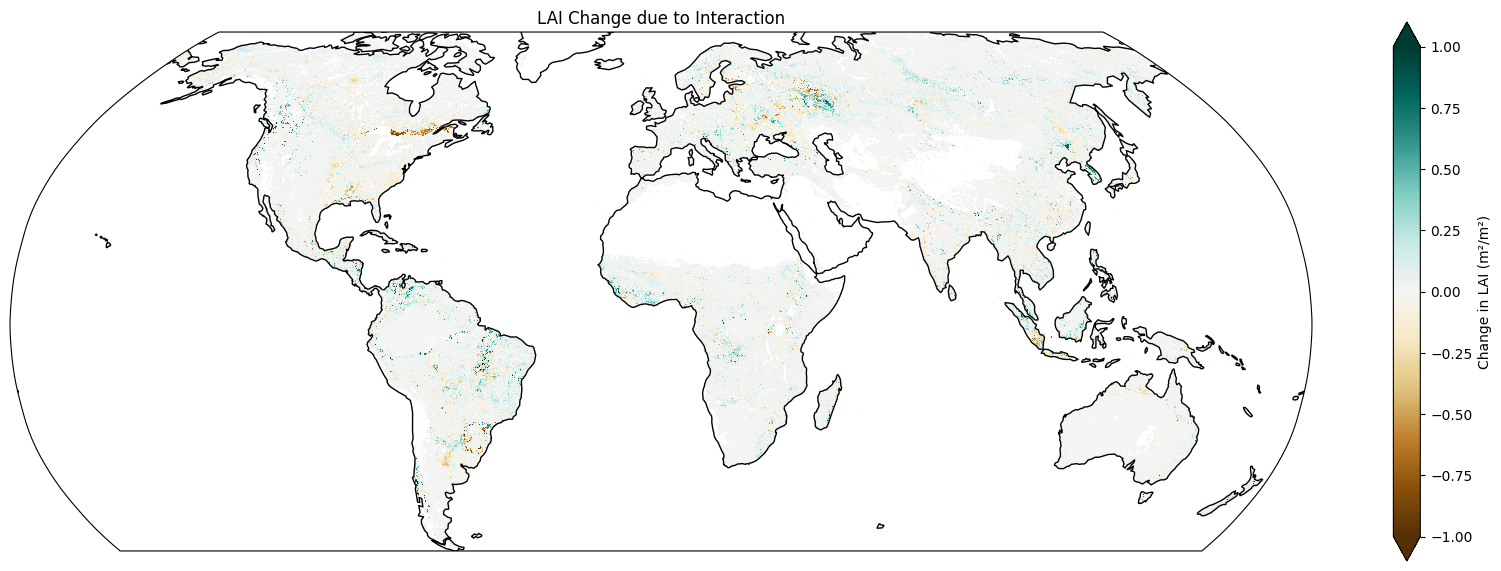

In [7]:
plot_map(deltaLAI, title='Total LAI Change', cmap='BrBG', vmin=-1, vmax=1, borders=False, cbar_label='Change in LAI (m²/m²)')
plot_map(deltaLAI_clim, title='LAI Change due to Climate', cmap='BrBG', vmin=-1, vmax=1, borders=False, cbar_label='Change in LAI (m²/m²)')
plot_map(deltaLAI_lu, title='LAI Change due to Land Use', cmap='BrBG', vmin=-1, vmax=1, borders=False, cbar_label='Change in LAI (m²/m²)')
plot_map(deltaLAI_interaction, title='LAI Change due to Interaction', cmap='BrBG', vmin=-1, vmax=1, borders=False, cbar_label='Change in LAI (m²/m²)')

In [11]:
lai_1990_pred = xr.open_dataset('../output_lai/lai_historical_ensemble_mean.nc')
lai_2020_pred = xr.open_dataset('../output_lai/lai_present_oos_mosaic.nc')
laiChangePred = lai_2020_pred.lai_95th - lai_1990_pred.lai_95th

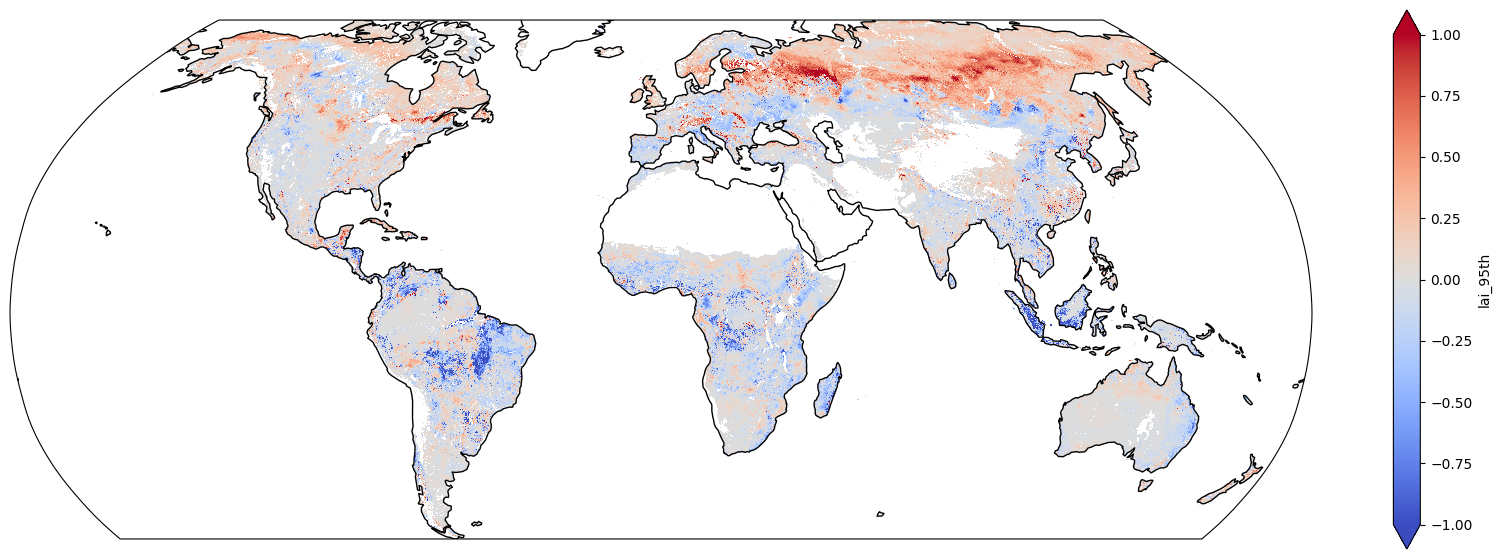

In [12]:
plot_map(laiChangePred, vmin=-1, vmax=1, cmap='coolwarm')

In [8]:
lai_1990_obs = xr.open_dataset('../data/LAI_mean_95th_1982_1990.nc')
lai_2020_obs = xr.open_dataset('../data/LAI_mean_95th_2011_2015.nc')
laiChangeObs = lai_2020_obs.lai_95th - lai_1990_obs.lai_95th

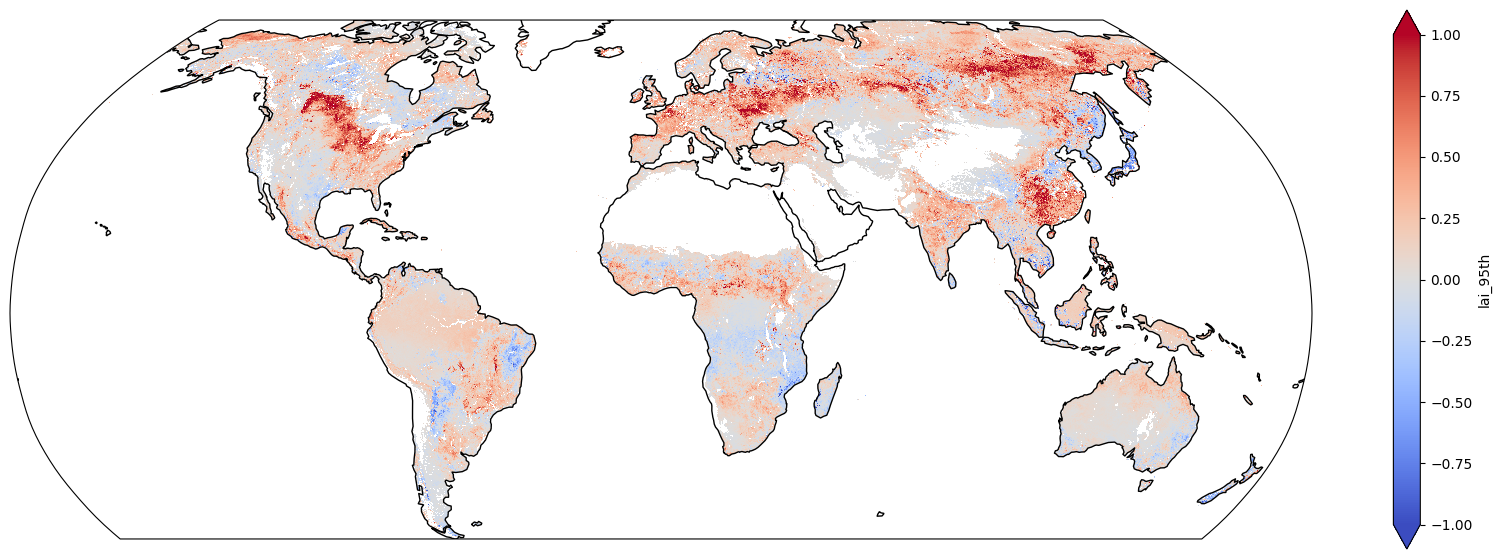

In [13]:
plot_map(laiChangeObs, vmin=-1, vmax=1, cmap='coolwarm')

In [14]:
changeDiff = laiChangeObs - laiChangePred

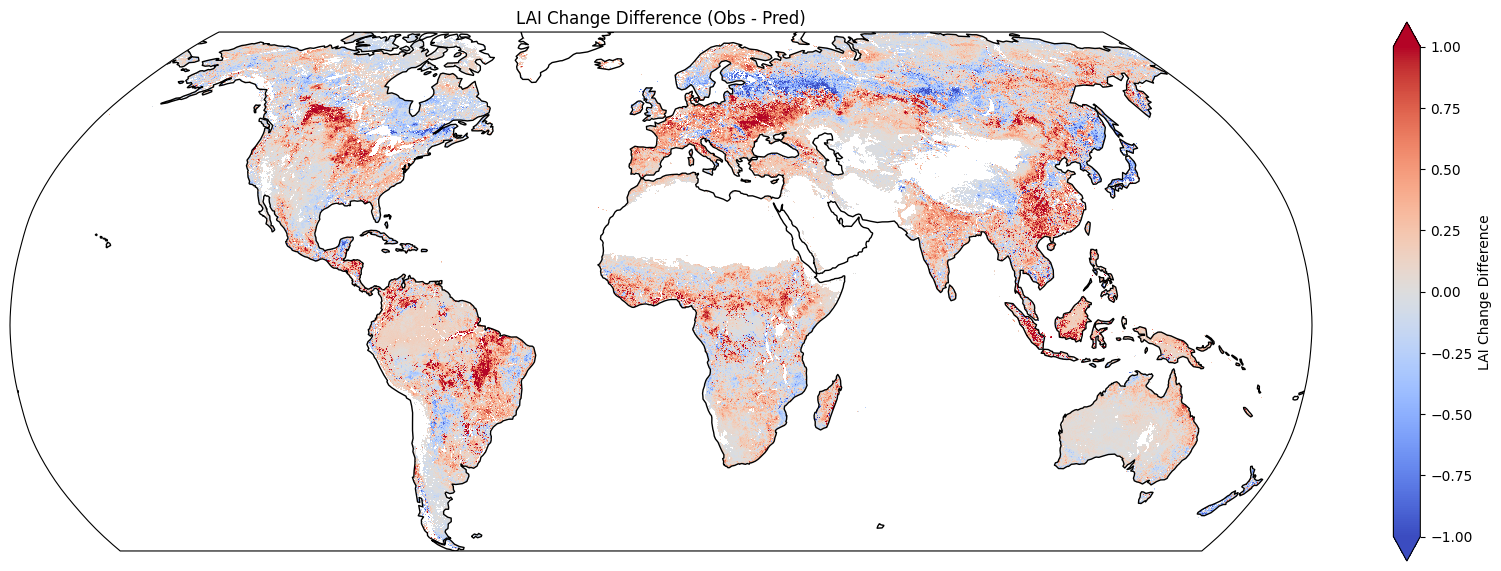

In [15]:
plot_map(changeDiff, vmin=-1, vmax=1, cmap='coolwarm', title='LAI Change Difference (Obs - Pred)', cbar_label='LAI Change Difference')

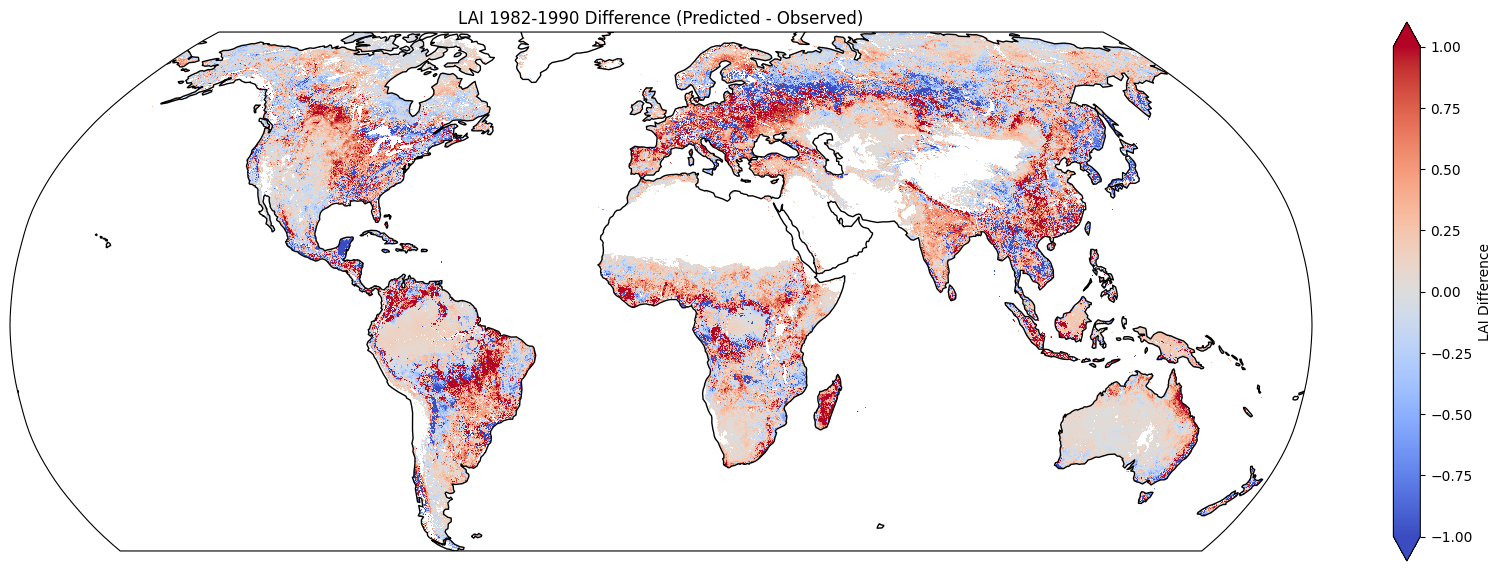

In [6]:
plot_map(lai_1990_pred.lai_95th - lai_1990_obs.lai_95th, vmin=-1, vmax=1, cmap='coolwarm', title='LAI 1982-1990 Difference (Predicted - Observed)', cbar_label='LAI Difference')

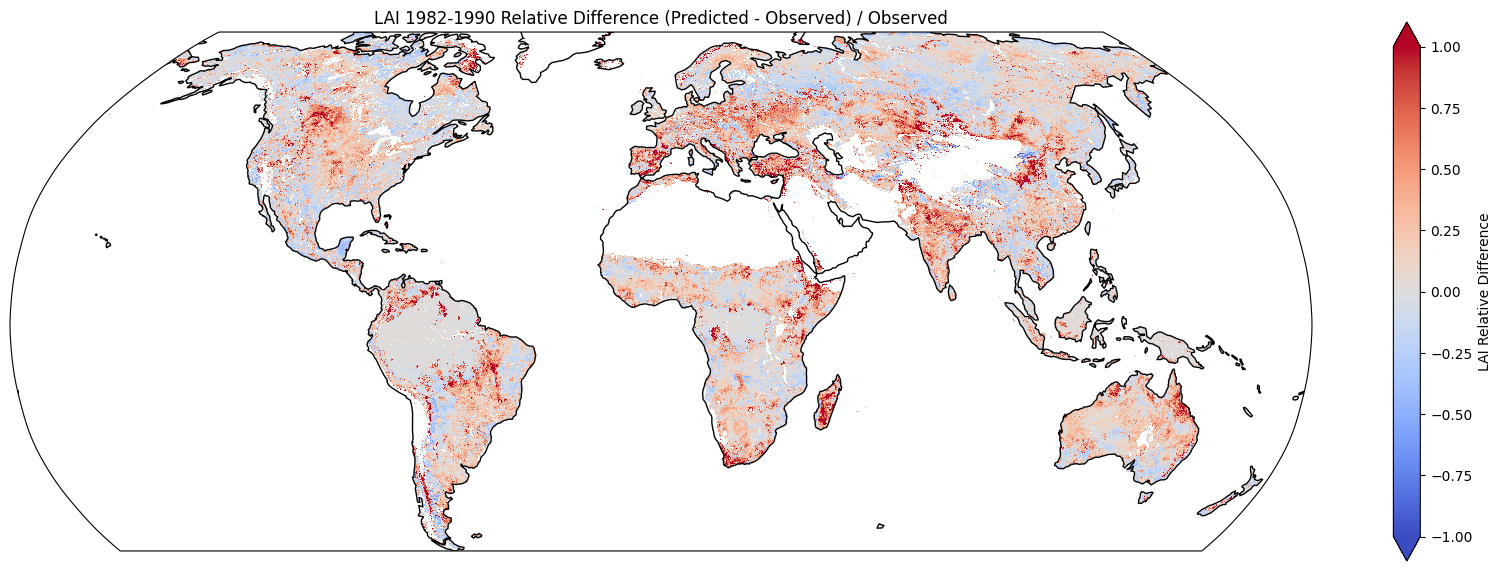

In [8]:
plot_map((lai_1990_pred.lai_95th - lai_1990_obs.lai_95th) / lai_1990_obs.lai_95th, vmin=-1, vmax=1, cmap='coolwarm', title='LAI 1982-1990 Relative Difference (Predicted - Observed) / Observed', cbar_label='LAI Relative Difference')

In [22]:
albedo_1990_pred = xr.open_dataset('../output_albedo/albedo_historical_ensemble_mean.nc')
albedo_2020_pred = xr.open_dataset('../output_albedo/albedo_present_oos_mosaic.nc')
albedoChangePred = albedo_2020_pred.albedo_10th - albedo_1990_pred.albedo_10th

albedo_1990_obs = xr.open_dataset('../data/albedo_mean_10th_1981_1990.nc')
albedo_2020_obs = xr.open_dataset('../data/albedo_mean_10th_2011_2020.nc')
albedoChangeObs = albedo_2020_obs.albedo_10th - albedo_1990_obs.albedo_10th

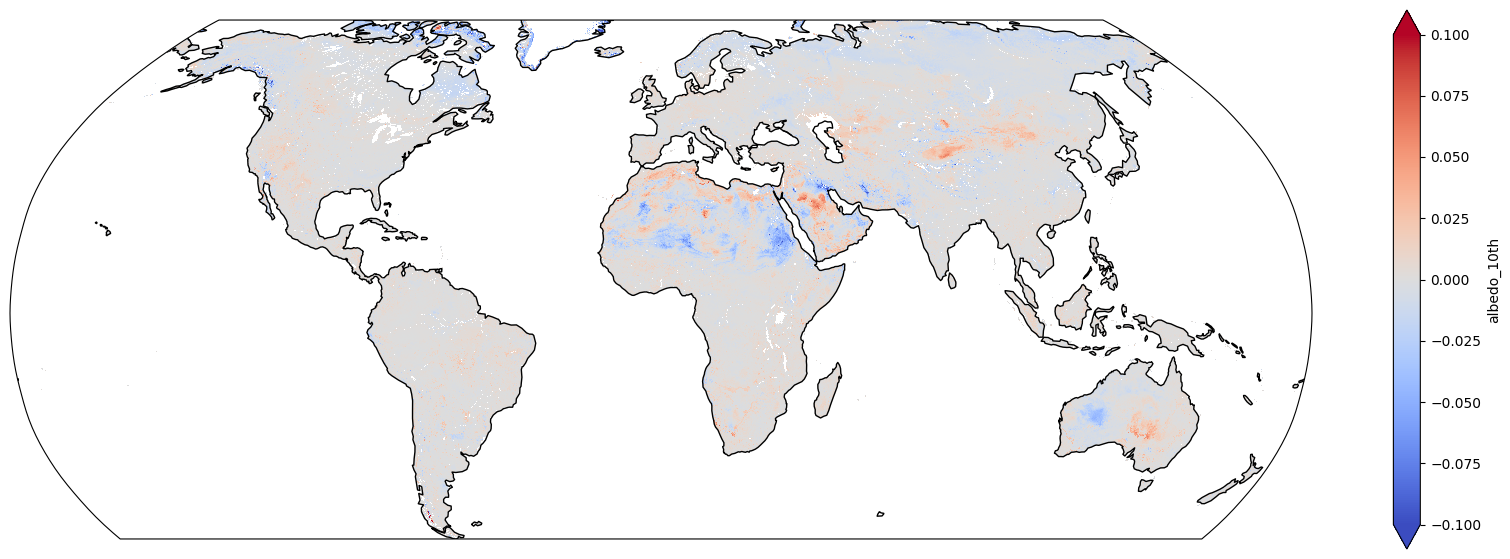

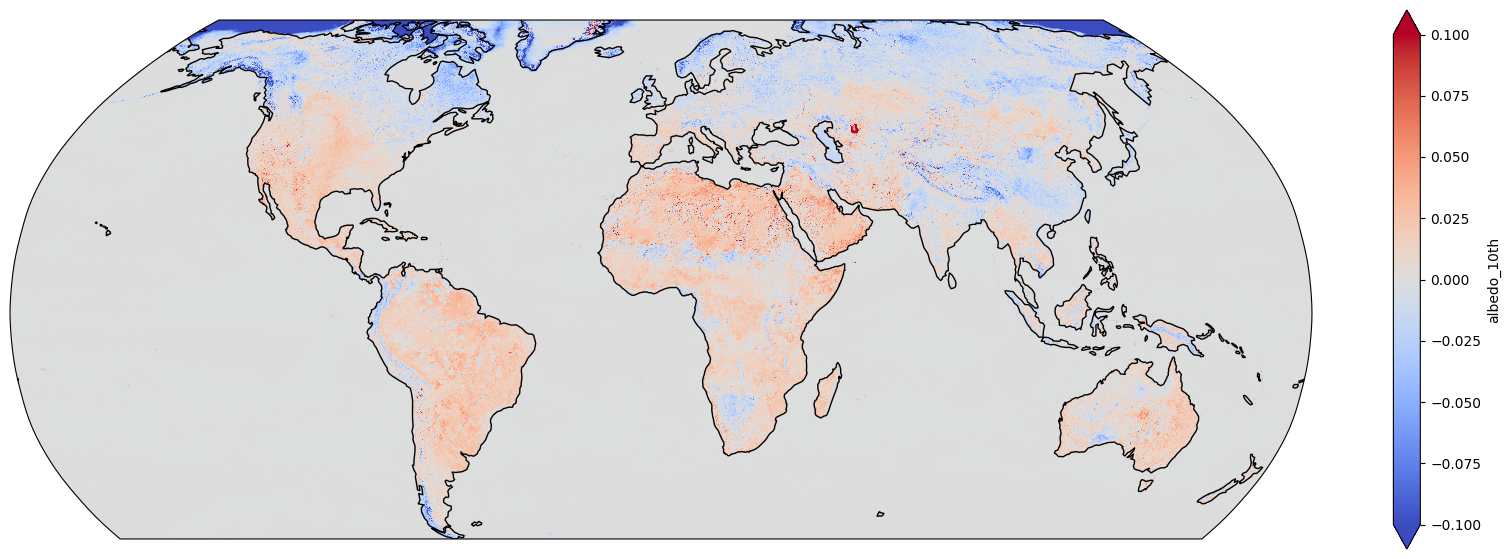

In [24]:
plot_map(albedoChangePred, vmin=-0.1, vmax=0.1, cmap='coolwarm')
plot_map(albedoChangeObs, vmin=-0.1, vmax=0.1, cmap='coolwarm')